In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\geeth\OneDrive\Desktop\Data Analysis Projects\Netflix Project\netflix_content_2023.csv")
print(df.head(10))


                                 Title Available Globally? Release Date  \
0            The Night Agent: Season 1                 Yes   2023-03-23   
1            Ginny & Georgia: Season 2                 Yes   2023-01-05   
2   The Glory: Season 1 // 더 글로리: 시즌 1                 Yes   2022-12-30   
3                  Wednesday: Season 1                 Yes   2022-11-23   
4  Queen Charlotte: A Bridgerton Story                 Yes   2023-05-04   
5                        You: Season 4                 Yes   2023-02-09   
6           La Reina del Sur: Season 3                  No   2022-12-30   
7                Outer Banks: Season 3                 Yes   2023-02-23   
8            Ginny & Georgia: Season 1                 Yes   2021-02-24   
9                      FUBAR: Season 1                 Yes   2023-05-25   

   Hours Viewed Language Indicator Content Type  
0  81,21,00,000            English         Show  
1  66,51,00,000            English         Show  
2  62,28,00,000         

In [32]:
print(df.info())
print(df.shape)
print(df.columns)
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 24812 entries, 0 to 24811
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Title                24812 non-null  str  
 1   Available Globally?  24812 non-null  str  
 2   Release Date         8166 non-null   str  
 3   Hours Viewed         24812 non-null  str  
 4   Language Indicator   24812 non-null  str  
 5   Content Type         24812 non-null  str  
dtypes: str(6)
memory usage: 1.1 MB
None
(24812, 6)
Index(['Title', 'Available Globally?', 'Release Date', 'Hours Viewed',
       'Language Indicator', 'Content Type'],
      dtype='str')
Title                  str
Available Globally?    str
Release Date           str
Hours Viewed           str
Language Indicator     str
Content Type           str
dtype: object


In [33]:
print(df.isnull().sum())


Title                      0
Available Globally?        0
Release Date           16646
Hours Viewed               0
Language Indicator         0
Content Type               0
dtype: int64


In [34]:
print(df.duplicated().sum())

467


In [35]:
print(df['Hours Viewed'].head(10))

0    81,21,00,000
1    66,51,00,000
2    62,28,00,000
3    50,77,00,000
4    50,30,00,000
5    44,06,00,000
6    42,96,00,000
7    40,25,00,000
8    30,21,00,000
9    26,62,00,000
Name: Hours Viewed, dtype: str


In [36]:
print(df[df.duplicated()].head(10))

                                                   Title Available Globally?  \
18646                                 Seinfeld: Season 4                 Yes   
18678                          Friends (1994): Season 10                  No   
18694                        The InBESTigators: Season 1                 Yes   
19027                                     Safe: Season 1                 Yes   
19080                                     LEGO City 2018                  No   
19082                       LEGO City: Where Ravens Crow                  No   
19110                                Big Mouth: Season 2                 Yes   
19314                       The Big Show Show: Christmas                 Yes   
19316            Mighty Little Bheem: Diwali: Collection                 Yes   
19363  The Epic Tales of Captain Underpants in Space:...                 Yes   

      Release Date Hours Viewed Language Indicator Content Type  
18646          NaN  4,28,00,000            English   

In [37]:
print(df['Hours Viewed'].dtype)

str


In [38]:
print(df['Release Date'].head(20))

0     2023-03-23
1     2023-01-05
2     2022-12-30
3     2022-11-23
4     2023-05-04
5     2023-02-09
6     2022-12-30
7     2023-02-23
8     2021-02-24
9     2023-05-25
10    2022-11-04
11    2023-01-01
12    2022-12-02
13    2023-05-12
14    2023-01-24
15    2023-01-14
16    2023-03-24
17    2023-04-06
18    2023-04-20
19    2023-03-10
Name: Release Date, dtype: str


In [39]:
df=df.drop_duplicates()
df["Hours Viewed"]=df["Hours Viewed"].str.replace(',','')
df["Hours Viewed"]=pd.to_numeric(df["Hours Viewed"])
df["Release Date"]=pd.to_datetime(df["Release Date"])

In [40]:
print(df.info())
print("***************************************")
print(df.isnull().sum())
print("***************************************")
print(df.duplicated().sum())

<class 'pandas.DataFrame'>
Index: 24345 entries, 0 to 24807
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Title                24345 non-null  str           
 1   Available Globally?  24345 non-null  str           
 2   Release Date         7975 non-null   datetime64[us]
 3   Hours Viewed         24345 non-null  int64         
 4   Language Indicator   24345 non-null  str           
 5   Content Type         24345 non-null  str           
dtypes: datetime64[us](1), int64(1), str(4)
memory usage: 1.3 MB


None
***************************************
Title                      0
Available Globally?        0
Release Date           16370
Hours Viewed               0
Language Indicator         0
Content Type               0
dtype: int64
***************************************
0


In [41]:
print(df[['Title','Hours Viewed']].head(10))

                                 Title  Hours Viewed
0            The Night Agent: Season 1     812100000
1            Ginny & Georgia: Season 2     665100000
2   The Glory: Season 1 // 더 글로리: 시즌 1     622800000
3                  Wednesday: Season 1     507700000
4  Queen Charlotte: A Bridgerton Story     503000000
5                        You: Season 4     440600000
6           La Reina del Sur: Season 3     429600000
7                Outer Banks: Season 3     402500000
8            Ginny & Georgia: Season 1     302100000
9                      FUBAR: Season 1     266200000


In [42]:
content_views=df.groupby('Content Type')['Hours Viewed'].sum()
print(content_views)

Content Type
Movie     50543800000
Show     107426900000
Name: Hours Viewed, dtype: int64


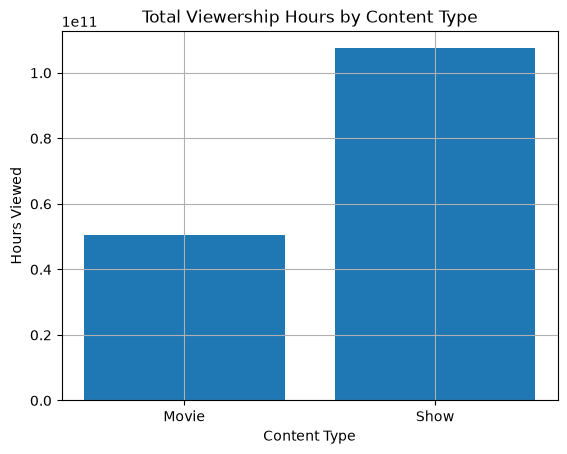

In [43]:
plt.bar(content_views.index,content_views.values)
plt.title("Total Viewership Hours by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Hours Viewed")
plt.grid(True)
plt.show()

In [44]:
language_views=df.groupby('Language Indicator')['Hours Viewed'].sum()
print(language_views)

Language Indicator
English        124092000000
Hindi             915000000
Japanese         7063300000
Korean          15371100000
Non-English     10414700000
Russian           114600000
Name: Hours Viewed, dtype: int64


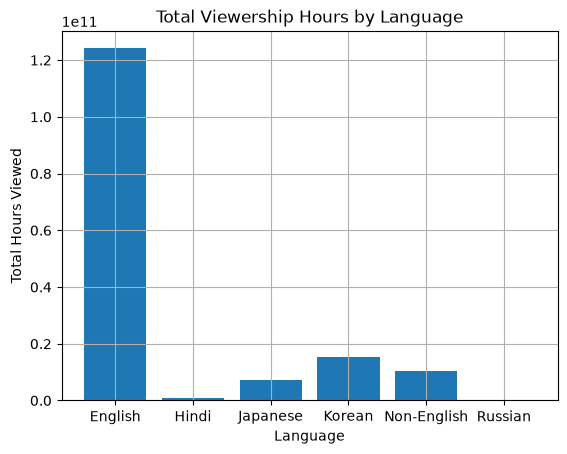

In [45]:
plt.bar(language_views.index,language_views.values)
plt.title("Total Viewership Hours by Language")
plt.xlabel("Language")
plt.ylabel("Total Hours Viewed")
plt.grid(True)
plt.show()

In [46]:
df["Release Month"]=df["Release Date"].astype(str).str[5:7]
df["Release Month"]=pd.to_numeric(df["Release Month"])
print(df[["Release Date","Release Month"]].head(10))

  Release Date  Release Month
0   2023-03-23            3.0
1   2023-01-05            1.0
2   2022-12-30           12.0
3   2022-11-23           11.0
4   2023-05-04            5.0
5   2023-02-09            2.0
6   2022-12-30           12.0
7   2023-02-23            2.0
8   2021-02-24            2.0
9   2023-05-25            5.0


In [47]:
monthly_views=df.groupby('Release Month')['Hours Viewed'].sum()
print(monthly_views)

Release Month
1.0      7265400000
2.0      7096000000
3.0      7425200000
4.0      6858600000
5.0      7068000000
6.0      8511100000
7.0      6513000000
8.0      6787800000
9.0      7254400000
10.0     8104700000
11.0     7739100000
12.0    10044500000
Name: Hours Viewed, dtype: int64


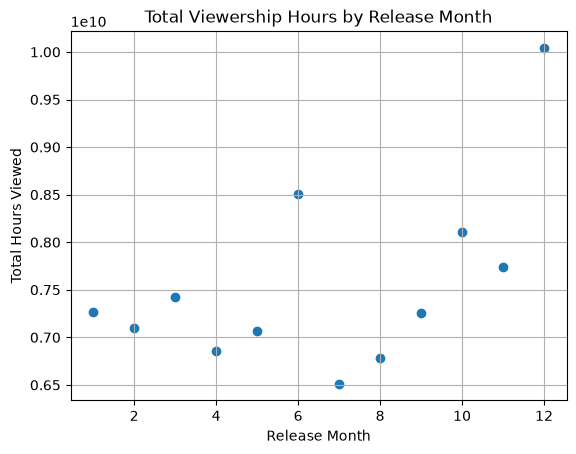

In [48]:
plt.scatter(monthly_views.index,monthly_views.values)
plt.title("Total Viewership Hours by Release Month")
plt.xlabel("Release Month")
plt.ylabel("Total Hours Viewed")
plt.grid(True)
plt.show()

In [49]:
top5=df.sort_values('Hours Viewed',ascending=False)
print(top5[['Title','Hours Viewed']].head())

                                                 Title  Hours Viewed
0                            The Night Agent: Season 1     812100000
1                            Ginny & Georgia: Season 2     665100000
18227  King the Land: Limited Series // 킹더랜드: 리미티드 시리즈     630200000
2                   The Glory: Season 1 // 더 글로리: 시즌 1     622800000
18214                              ONE PIECE: Season 1     541900000


In [50]:
movie_month=df[df['Content Type']=='Movie'].groupby('Release Month')['Hours Viewed'].sum()
print(movie_month)

Release Month
1.0     2275000000
2.0     1652600000
3.0     2103600000
4.0     2756900000
5.0     2515700000
6.0     3129500000
7.0     1613500000
8.0     2183900000
9.0     2089400000
10.0    3395300000
11.0    1862300000
12.0    2551300000
Name: Hours Viewed, dtype: int64


In [51]:
show_month=df[df['Content Type']=='Show'].groupby('Release Month')['Hours Viewed'].sum()
print(show_month)

Release Month
1.0     4990400000
2.0     5443400000
3.0     5321600000
4.0     4101700000
5.0     4552300000
6.0     5381600000
7.0     4899500000
8.0     4603900000
9.0     5165000000
10.0    4709400000
11.0    5876800000
12.0    7493200000
Name: Hours Viewed, dtype: int64


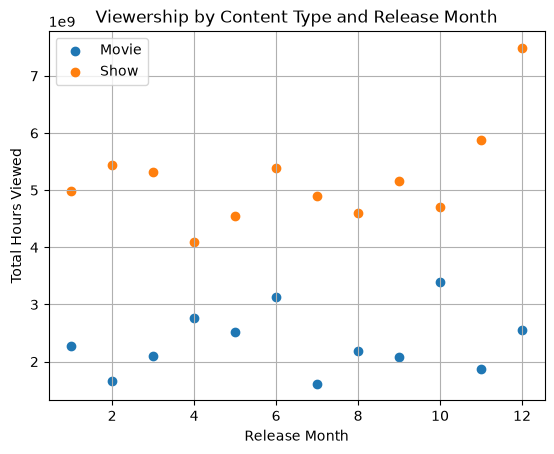

In [52]:
plt.scatter(movie_month.index,movie_month.values,label="Movie")
plt.scatter(show_month.index,show_month.values,label="Show")
plt.title("Viewership by Content Type and Release Month")
plt.xlabel("Release Month")
plt.ylabel("Total Hours Viewed")
plt.legend()
plt.grid(True)
plt.show()


In [53]:
def get_season(month):
    if month in [12,1,2]:
        return "Winter"
    elif month in [3,4,5]:
        return "Spring"
    elif month in [6,7,8]:
            return "Summer"
    else:
         return "Fall"

df["Release Season"]=df["Release Month"].apply(get_season)
print(df[["Release Month","Release Season"]].head(10))
    

   Release Month Release Season
0            3.0         Spring
1            1.0         Winter
2           12.0         Winter
3           11.0           Fall
4            5.0         Spring
5            2.0         Winter
6           12.0         Winter
7            2.0         Winter
8            2.0         Winter
9            5.0         Spring


In [54]:
season_views=df.groupby('Release Season')['Hours Viewed'].sum()
print(season_views)

Release Season
Fall      90401100000
Spring    21351800000
Summer    21811900000
Winter    24405900000
Name: Hours Viewed, dtype: int64


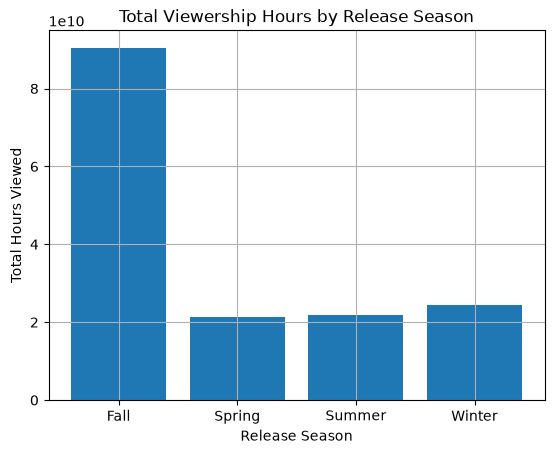

In [55]:
plt.bar(season_views.index,season_views.values)
plt.title("Total Viewership Hours by Release Season")
plt.xlabel("Release Season")
plt.ylabel("Total Hours Viewed")
plt.grid(True)
plt.show()

In [56]:
monthly_release=df.groupby("Release Month")["Title"].count()
print(monthly_release)

Release Month
1.0     598
2.0     543
3.0     678
4.0     630
5.0     611
6.0     655
7.0     616
8.0     656
9.0     726
10.0    786
11.0    719
12.0    757
Name: Title, dtype: int64


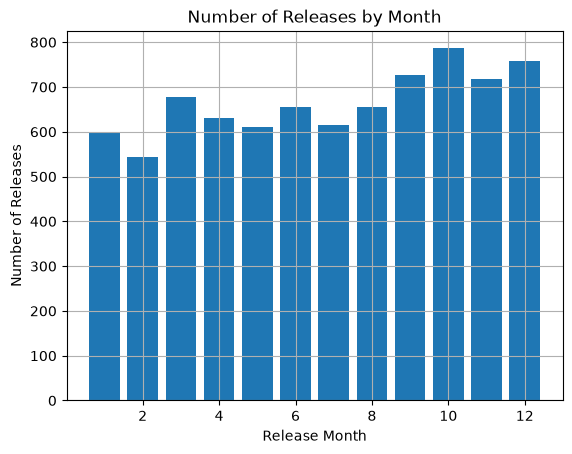

In [57]:
plt.bar(monthly_release.index,monthly_release.values)
plt.title("Number of Releases by Month")
plt.xlabel("Release Month")
plt.ylabel("Number of Releases")
plt.grid(True)
plt.show()

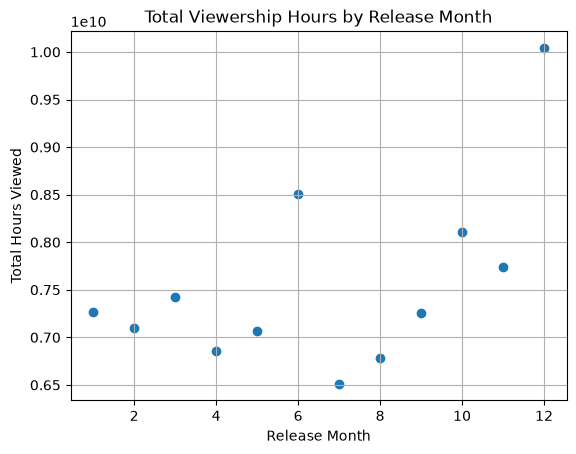

In [58]:
plt.scatter(monthly_views.index,monthly_views.values)
plt.title("Total Viewership Hours by Release Month")
plt.xlabel("Release Month")
plt.ylabel("Total Hours Viewed")
plt.grid(True)
plt.show()

In [66]:
df["Year"]=df["Release Date"].astype(str).str[0:4]
df_2023=df[df["Year"]=='2023']
print(df_2023["Year"].value_counts())

Year
2023    786
Name: count, dtype: int64


In [69]:
df_2023["Month"]=pd.to_numeric(df_2023["Release Date"].astype(str).str[5:7])
df_2023["Day"]=pd.to_numeric(df_2023["Release Date"].astype(str).str[8:10])

def days_bef_mon(month):
    if month==1:
        return 0
    elif month==2:
        return 31
    elif month==3:
        return 59
    elif month==4:
        return 90
    elif month == 5:
        return 120
    elif month == 6:
        return 151
    elif month == 7:
        return 181
    elif month == 8:
        return 212
    elif month == 9:
        return 243
    elif month == 10:
        return 273
    elif month == 11:
        return 304
    else:
        return 334

df_2023['Day of Year'] = df_2023['Month'].apply(days_bef_mon) + df_2023['Day']
df_2023['Week'] = ((df_2023['Day of Year'] - 1) // 7) + 1
weekly_releases = df_2023.groupby('Week')['Title'].count()
weekly_views = df_2023.groupby('Week')['Hours Viewed'].sum()
print(weekly_releases.head(10))
print("********************")
print(weekly_views.head(10))
    

Week
1     17
2     23
3     23
4     20
5     19
6     11
7     37
8     22
9     28
10    11
Name: Title, dtype: int64
********************
Week
1     1279000000
2      836300000
3      568200000
4     1070600000
5      378000000
6      882600000
7      961700000
8     1164800000
9      826200000
10     533700000
Name: Hours Viewed, dtype: int64


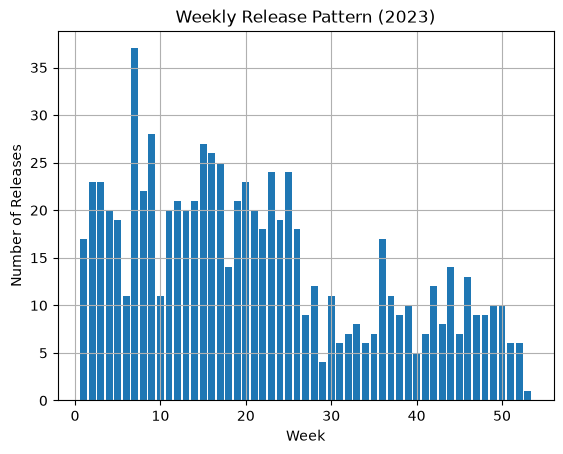

In [70]:
plt.bar(weekly_releases.index, weekly_releases.values)
plt.title('Weekly Release Pattern (2023)')
plt.xlabel('Week')
plt.ylabel('Number of Releases')
plt.grid(True)
plt.show()

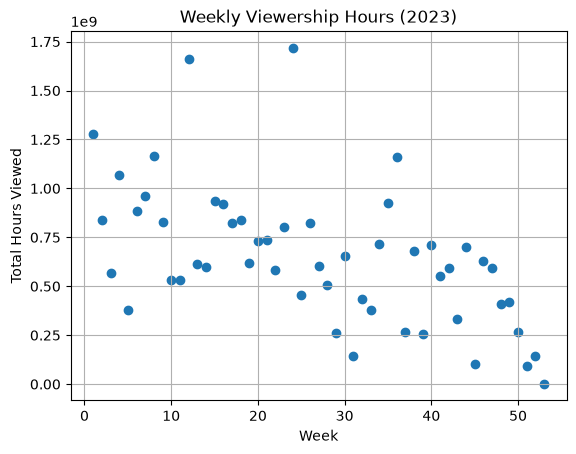

In [71]:
plt.scatter(weekly_views.index, weekly_views.values)
plt.title('Weekly Viewership Hours (2023)')
plt.xlabel('Week')
plt.ylabel('Total Hours Viewed')
plt.grid(True)
plt.show()

In [72]:
df["Month"]=pd.to_numeric(df["Release Date"].astype(str).str[5:7])
df["Day"]=pd.to_numeric(df["Release Date"].astype(str).str[8:10])

holiday_release=df[((df["Month"]==1)&(df["Day"]==1)) | ((df["Month"]==2)&(df["Day"]==14)) | ((df["Month"]==7)&(df["Day"]==4)) | ((df["Month"]==12)&(df["Day"]==25)) ]
print(holiday_release[["Title","Release Date","Content Type","Hours Viewed"]])


                                                   Title Release Date  \
11                          Kaleidoscope: Limited Series   2023-01-01   
29                               Perfect Match: Season 1   2023-02-14   
56                                  Bridgerton: Season 1   2020-12-25   
140                     Roald Dahl's Matilda The Musical   2022-12-25   
190                                    Stranger Things 3   2019-07-04   
...                                                  ...          ...   
24572  Stories of a Generation - with Pope Francis: L...   2021-12-25   
24577                          The Big Day: Collection 1   2021-02-14   
24623                              Chris Rock: Tamborine   2018-02-14   
24701                         Katherine Ryan: In Trouble   2017-02-14   
24703                     Ken Jeong: You Complete Me, Ho   2019-02-14   

      Content Type  Hours Viewed  
11           Movie     252500000  
29            Show     176800000  
56            Show

In [73]:
def get_holiday(month, day):
    if month == 1 and day == 1:
        return 'New Year'
    elif month == 2 and day == 14:
        return 'Valentines Day'
    elif month == 7 and day == 4:
        return 'Independence Day'
    elif month == 12 and day == 25:
        return 'Christmas'
    else:
        return 'Other'

holiday_release['Holiday'] = holiday_release.apply(lambda row: get_holiday(row['Month'], row['Day']), axis=1)
print(holiday_release[['Title', 'Release Date', 'Holiday', 'Content Type', 'Hours Viewed']])


                                                   Title Release Date  \
11                          Kaleidoscope: Limited Series   2023-01-01   
29                               Perfect Match: Season 1   2023-02-14   
56                                  Bridgerton: Season 1   2020-12-25   
140                     Roald Dahl's Matilda The Musical   2022-12-25   
190                                    Stranger Things 3   2019-07-04   
...                                                  ...          ...   
24572  Stories of a Generation - with Pope Francis: L...   2021-12-25   
24577                          The Big Day: Collection 1   2021-02-14   
24623                              Chris Rock: Tamborine   2018-02-14   
24701                         Katherine Ryan: In Trouble   2017-02-14   
24703                     Ken Jeong: You Complete Me, Ho   2019-02-14   

                Holiday Content Type  Hours Viewed  
11             New Year        Movie     252500000  
29       Valentin

Holiday
Christmas           20
Independence Day     6
New Year            34
Valentines Day      47
Name: Title, dtype: int64


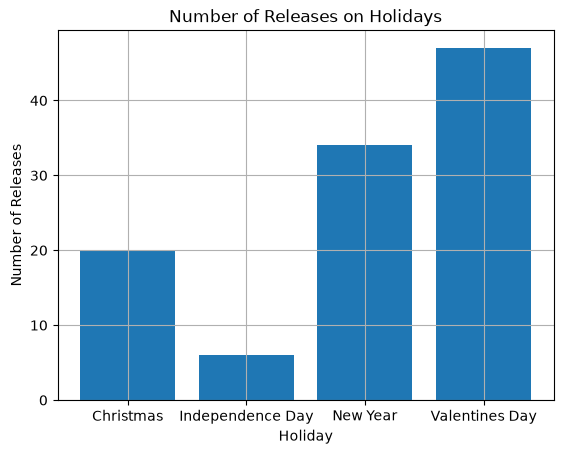

In [74]:
holiday_count = holiday_release.groupby('Holiday')['Title'].count()
print(holiday_count)
plt.bar(holiday_count.index, holiday_count.values)
plt.title('Number of Releases on Holidays')
plt.xlabel('Holiday')
plt.ylabel('Number of Releases')
plt.grid(True)
plt.show()